# Stairway codes — logical error rate vs $p_z$ (fixed $p_{\text{res}}$)

Curves of logical error rate (per observable) vs Bell-pair $Z$ error rate `p_bell_z` for each
`[[n,k,d]]` stairway code, at a **fixed** residual noise `p_res`. This is a single vertical slice of
the `(p_res, p_z)` grid — the same slice `tools/_grid_scans/plot_grid.py` draws — rendered in the
sinter-plotter style of `high_rate_stairway.ipynb`.

Data source: `out/collection/grid_stairway*.csv` (decoded with Tesseract). Multiple schemes
(`equivalent_v3`, `equivalent_v3_majority5`, ...) coexist in the CSVs and are distinguished by the
`noise_model` metadata column; each gets its own linestyle.

In [1]:
import ast
import datetime
import glob
import json
import re
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import sinter

# Reuse the shared paper rcParams so this figure matches the high-rate figures.
from high_rate_analysis import set_paper_style

%load_ext autoreload
%autoreload 2

In [2]:
# ---- Config -----------------------------------------------------------------
CSV_GLOB = '../out/collection/grid_stairway*.csv'
P_RES = 1e-4        # fixed residual-noise slice (snapped to nearest sampled value)

# Legend labels + linestyle per scheme (noise_model column). Extend when you add
# more schemes (e.g. equivalent_v3_majority).
SCHEME_LABEL = {
    'biased_bell_v3_equivalent': '1-rep',
    'biased_bell_v3_equivalent_majority': '3-rep majority',
    'biased_bell_v3_equivalent_majority5': '5-rep majority',
}
SCHEME_LS = {
    'biased_bell_v3_equivalent': '-',
    'biased_bell_v3_equivalent_majority': '--',
    'biased_bell_v3_equivalent_majority5': ':',
}

In [3]:
def _parse_meta(s):
    """Parse a json_metadata cell: sinter CSV (JSON) or dated pandas CSV (repr)."""
    if not isinstance(s, str):
        return dict(s)
    try:
        return json.loads(s)
    except (json.JSONDecodeError, ValueError):
        return ast.literal_eval(s)


_AGG = {
    'shots': 'sum', 'errors': 'sum', 'discards': 'sum', 'seconds': 'sum',
    'decoder': 'first', 'json_metadata': 'first',
}


def load_slice(csv_glob, p_res):
    """Load grid_stairway CSV(s), merge repeated runs, keep one p_res slice.

    Returns (df, p_res_used, code_order). The two CSV formats (sinter-JSON from
    --resume and dated pandas-repr from append mode) are merged by strong_id, so
    shots/errors for the same task accumulate across files.
    """
    files = sorted(f for f in glob.glob(csv_glob))
    if not files:
        raise FileNotFoundError(f'No files matched: {csv_glob}')
    # skipinitialspace: sinter's CSV header pads column names with spaces.
    df = pd.concat([pd.read_csv(f, skipinitialspace=True) for f in files],
                   ignore_index=True)
    df = df.groupby('strong_id').agg(_AGG).reset_index()

    meta = df['json_metadata'].apply(_parse_meta)
    for c in ('p', 'p_bell_z', 'noise_model', 'n', 'k'):
        df[c] = meta.apply(lambda m, c=c: m.get(c))
    df['d'] = meta.apply(lambda m: m.get('expected_distance', m.get('d')))
    df['code'] = df.apply(
        lambda r: f"[[{int(r['n'])},{int(r['k'])},{int(r['d'])}]]", axis=1)

    # Snap the requested p_res to the nearest actually-sampled value.
    avail = np.array(sorted(df['p'].dropna().unique()))
    p_used = float(avail[np.argmin(np.abs(avail - p_res))])
    df = df[np.isclose(df['p'].astype(float), p_used)].reset_index(drop=True)

    code_order = df.drop_duplicates('code').sort_values('n')['code'].tolist()
    return df, p_used, code_order


def df_to_tasks(df):
    """Rebuild sinter.TaskStats from merged rows (n/k/d injected into metadata)."""
    tasks = []
    for _, row in df.iterrows():
        m = _parse_meta(row['json_metadata'])
        m['n'], m['k'], m['expected_distance'] = int(row['n']), int(row['k']), int(row['d'])
        tasks.append(sinter.TaskStats(
            strong_id=row['strong_id'], decoder=row['decoder'], json_metadata=m,
            shots=int(row['shots']), errors=int(row['errors']),
            discards=int(row['discards']), seconds=float(row['seconds']),
        ))
    return tasks


df, p_used, code_order = load_slice(CSV_GLOB, P_RES)
schemes = [s for s in SCHEME_LABEL if s in set(df['noise_model'].dropna())]
schemes += [s for s in df['noise_model'].dropna().unique() if s not in schemes]
print(f'{len(df)} rows at p_res={p_used:g} (requested {P_RES:g})')
print(f'codes: {code_order}')
print(f'schemes: {schemes}')
print(f'p_z range: {df["p_bell_z"].min():.3g} .. {df["p_bell_z"].max():.3g} '
      f'({df["p_bell_z"].nunique()} values)')
df.head()

141 rows at p_res=0.0001 (requested 0.0001)
codes: ['[[192,16,4]]', '[[192,6,9]]', '[[288,14,10]]']
schemes: ['biased_bell_v3_equivalent', 'biased_bell_v3_equivalent_majority5']
p_z range: 0.0001 .. 0.1 (35 values)


,strong_id,shots,errors,discards,seconds,decoder,json_metadata,p,p_bell_z,noise_model,n,k,d,code
0,04d0078534ed747b7d75f678e3fca4be139592f5aaa422...,90000,12,0,5258.920350,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.0001,0.010000,biased_bell_v3_equivalent_majority5,192.0,16.0,4,"[[192,16,4]]"
1,0779a576314faa387509dbb19cdf40edf3642426c38cc5...,80000,0,0,15370.627992,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.0001,0.001520,biased_bell_v3_equivalent_majority5,192.0,6.0,9,"[[192,6,9]]"
2,0d1acec0c3b0c58518bee435948aca950a8909cf7a3481...,80000,13,0,4022.926467,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.0001,0.002310,biased_bell_v3_equivalent_majority5,192.0,16.0,4,"[[192,16,4]]"
3,0e3c136d8b6324d51ad8a708bdbea73606156f1a1e24b7...,140000,5,0,70429.049645,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.0001,0.001874,biased_bell_v3_equivalent,288.0,14.0,10,"[[288,14,10]]"
4,0f8ca60878cdfcd9cd58e4b462478c7763981a469a5411...,90000,13,0,4521.166064,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.0001,0.001233,biased_bell_v3_equivalent_majority5,192.0,16.0,4,"[[192,16,4]]"


Saved ../out/figures/20260719_stairway_grid_pres0.0001.pdf


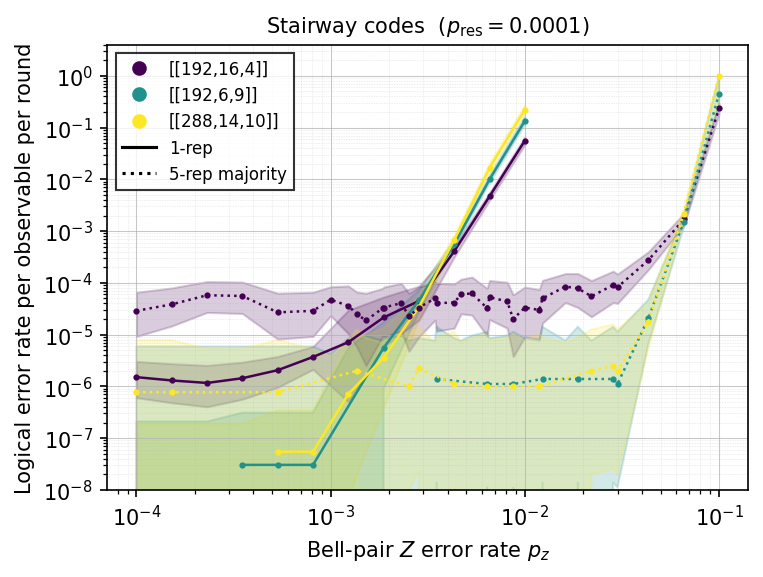

In [14]:
# LER (per observable) vs p_z at fixed p_res. Color = code (viridis, ordered by
# n); linestyle = scheme. Drawn with sinter.plot_error_rate, like high_rate_stairway.
set_paper_style()

cmap = plt.get_cmap('viridis')
colors = {code: cmap(i / max(1, len(code_order) - 1))
          for i, code in enumerate(code_order)}

fig, ax = plt.subplots(1, 1, figsize=(5.2, 4))

for scheme in schemes:
    sdf = df[df['noise_model'] == scheme]
    if sdf.empty:
        continue
    ls = SCHEME_LS.get(scheme, '-')

    def plot_args_func(index, group_key, group_stats, _ls=ls):
        code = group_key.split(']]')[0].replace(' ', '') + ']]'
        return {'color': colors.get(code, 'k'), 'linestyle': _ls,
                'marker': '.', 'markersize': 4, 'linewidth': 1.2}

    sinter.plot_error_rate(
        ax=ax,
        stats=df_to_tasks(sdf),
        x_func=lambda s: s.json_metadata['p_bell_z'],
        group_func=lambda s: (f"[[{s.json_metadata['n']}, {s.json_metadata['k']}, "
                              f"{s.json_metadata['expected_distance']}]]"),
        plot_args_func=plot_args_func,
        failure_units_per_shot_func=lambda s: s.json_metadata['expected_distance'], 
        failure_values_func=lambda s: s.json_metadata['k'],
    )

ax.loglog()
ax.set_xlabel(r'Bell-pair $Z$ error rate $p_z$')
ax.set_ylabel(r'Logical error rate per observable per round')
ax.set_title(rf'Stairway codes  ($p_{{\text{{res}}}} = {p_used:g}$)')
ax.set_ylim(1e-8, 4)
ax.grid(which='major', linestyle='-', linewidth=0.5, alpha=0.7)
ax.grid(which='minor', linestyle=':', linewidth=0.3, alpha=0.5)

# Two-part legend: color = code, linestyle = scheme.
code_handles = [Line2D([0], [0], color=colors[c], marker='o', linestyle='',
                       label=c) for c in code_order]
scheme_handles = [Line2D([0], [0], color='k', linestyle=SCHEME_LS.get(s, '-'),
                         label=SCHEME_LABEL.get(s, s))
                  for s in schemes if not df[df['noise_model'] == s].empty]
ax.legend(handles=code_handles + scheme_handles, loc=None,
          fontsize=8, frameon=True, edgecolor='black', fancybox=False)

fig.tight_layout()
fig.set_dpi(150)

out_dir = Path('../out/figures')
out_dir.mkdir(parents=True, exist_ok=True)
date = datetime.date.today().strftime('%Y%m%d')
out_path = out_dir / f'{date}_stairway_grid_pres{p_used:g}.pdf'
fig.savefig(out_path, bbox_inches='tight')
print(f'Saved {out_path}')
plt.show()